In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/charging_sessions.csv")

In [3]:
# preparation that can later be omitted
df["connectionTime"] = pd.to_datetime(df["connectionTime"])
df["disconnectTime"] = pd.to_datetime(df["disconnectTime"])
df["doneChargingTime"] = pd.to_datetime(df["doneChargingTime"])

In [4]:
# Features that are already calculated in exploration:

# Add a column "endChargingTime" that holds the time when charging ended (doneChargingTime or disconnectTime if the doneChargingTime was null)
df["endChargingTime"] = df["doneChargingTime"].fillna(df["disconnectTime"])
# Charging duration (time actively charging)
df["chargingDurationMin"] = (df["endChargingTime"] - df["connectionTime"]).dt.total_seconds() / 60
# Idle time (time plugged in after charging finished)
df["blockingDurationMin"] = (df["disconnectTime"] - df["endChargingTime"]).dt.total_seconds() / 60

In [ ]:
# proposed features:

# 1. Charging time (total time plugged in)
df["charging_time_minutes"] = (df["disconnectTime"] - df["connectionTime"]).dt.total_seconds() / 60

# 2. Energy delivery rate (kW per hour)
df["energy_rate_kW"] = df["kWhDelivered"] / (df["chargingDurationMin"] / 60)

# 3. cyclical encoding of connectionTime and disconnectTime with sine/cosine

df["connection_hour"] = df["connectionTime"].dt.hour + df["connectionTime"].dt.minute / 60.0
df["disconnect_hour"] = df["disconnectTime"].dt.hour + df["disconnectTime"].dt.minute / 60.0

df["connection_hour_sin"] = np.sin(2 * np.pi * df["connection_hour"] / 24) 
df["connection_hour_cos"] = np.cos(2 * np.pi * df["connection_hour"] / 24) 

df["disconnect_hour_sin"] = np.sin(2 * np.pi * df["disconnect_hour"] / 24)
df["disconnect_hour_cos"] = np.cos(2 * np.pi * df["disconnect_hour"] / 24)

# 4. isWeekday

df["connection_isWeekday"] = df["connectionTime"].dt.dayofweek < 5

# 5. is User Registered?

df["isRegisteredUser"] = df["userID"].isna

TypeError: bad operand type for unary ~: 'method'

In [7]:
df[["connection_hour", "connection_hour_sin","connection_hour_cos"]]

,connection_hour,connection_hour_sin,connection_hour_cos
0,13.133333,-0.292372,-0.956305
1,13.600000,-0.406737,-0.913545
2,13.933333,-0.484810,-0.874620
3,13.983333,-0.496217,-0.868199
4,14.000000,-0.500000,-0.866025
...,...,...,...
66445,18.133333,-0.999391,0.034899
66446,18.666667,-0.984808,0.173648
66447,19.066667,-0.961262,0.275637
66448,19.316667,-0.941176,0.337917


<Axes: xlabel='connection_hour_sin', ylabel='Count'>

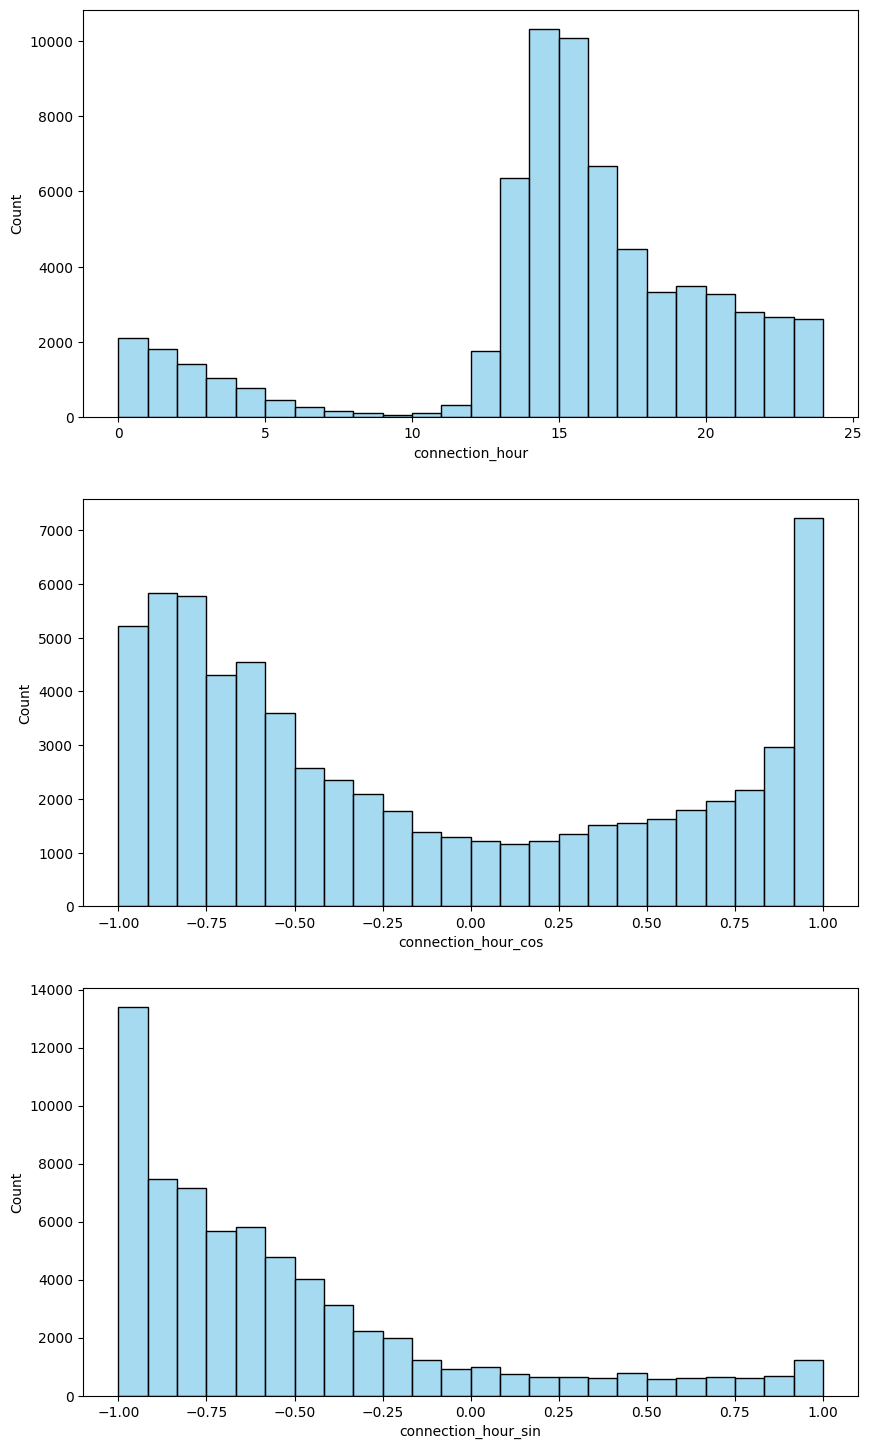

In [21]:
fig, axes = plt.subplots(3, 1, figsize=(10, 18), sharex=False)

sns.histplot(df['connection_hour'].astype(float), bins=24, kde=False, color='skyblue', ax=axes[0])
sns.histplot(df['connection_hour_cos'].astype(float), bins=24, kde=False, color='skyblue', ax=axes[1])
sns.histplot(df['connection_hour_sin'].astype(float), bins=24, kde=False, color='skyblue', ax=axes[2])